In [1]:
import pandas as pd

import numpy as np
import matplotlib.pyplot as plt
import os

print(os.listdir())

['README.md', '01_Data_Understanding_Cleaning.ipynb', '.ipynb_checkpoints', 'Model_Training.ipynb']


In [4]:
df = pd.read_csv("T_ONTIME_REPORTING.csv", low_memory=False)

print("Dataset Shape:", df.shape)

display(df.head())



Dataset Shape: (544003, 31)


,YEAR,QUARTER,MONTH,DAY_OF_MONTH,DAY_OF_WEEK,FL_DATE,OP_UNIQUE_CARRIER,OP_CARRIER_FL_NUM,ORIGIN_AIRPORT_ID,ORIGIN,...,CRS_ARR_TIME,ARR_TIME,ARR_DELAY,ARR_DEL15,ARR_TIME_BLK,CANCELLED,CANCELLATION_CODE,DIVERTED,CRS_ELAPSED_TIME,DISTANCE
0,2026,1,1,1,4,01/01/2026 0:00,AA,1,12478,JFK,...,1021,1104.0,43.0,1.0,1000-1059,0,NaN,0,381,2475
1,2026,1,1,1,4,01/01/2026 0:00,AA,10,12892,LAX,...,551,520.0,-31.0,0.0,0001-0559,0,NaN,0,321,2475
2,2026,1,1,1,4,01/01/2026 0:00,AA,1002,13303,MIA,...,2359,2356.0,-3.0,0.0,2300-2359,0,NaN,0,134,674
3,2026,1,1,1,4,01/01/2026 0:00,AA,1003,11292,DEN,...,527,508.0,-19.0,0.0,0001-0559,0,NaN,0,229,1709
4,2026,1,1,1,4,01/01/2026 0:00,AA,1004,10721,BOS,...,1030,1023.0,-7.0,0.0,1000-1059,0,NaN,0,153,728


In [5]:
# Prepare clean data for model training

df_clean = df.copy()

# Remove duplicate records
df_clean = df_clean.drop_duplicates()

# Remove cancelled and diverted flights
df_clean = df_clean[
    (df_clean["CANCELLED"] == 0) &
    (df_clean["DIVERTED"] == 0)
].copy()

# Keep valid target values
df_clean = df_clean[
    df_clean["ARR_DEL15"].isin([0, 1])
].copy()

# Remove invalid flight duration and distance
df_clean = df_clean[
    (df_clean["CRS_ELAPSED_TIME"] > 0) &
    (df_clean["DISTANCE"] > 0)
].copy()

df_clean["ARR_DEL15"] = df_clean["ARR_DEL15"].astype(int)

# Display cleaning results
print("Before Cleaning:", df.shape)
print("After Cleaning:", df_clean.shape)
print("Missing Target:", df_clean["ARR_DEL15"].isnull().sum())

display(df_clean.head())


Before Cleaning: (544003, 31)
After Cleaning: (517222, 31)
Missing Target: 0


,YEAR,QUARTER,MONTH,DAY_OF_MONTH,DAY_OF_WEEK,FL_DATE,OP_UNIQUE_CARRIER,OP_CARRIER_FL_NUM,ORIGIN_AIRPORT_ID,ORIGIN,...,CRS_ARR_TIME,ARR_TIME,ARR_DELAY,ARR_DEL15,ARR_TIME_BLK,CANCELLED,CANCELLATION_CODE,DIVERTED,CRS_ELAPSED_TIME,DISTANCE
0,2026,1,1,1,4,01/01/2026 0:00,AA,1,12478,JFK,...,1021,1104.0,43.0,1,1000-1059,0,NaN,0,381,2475
1,2026,1,1,1,4,01/01/2026 0:00,AA,10,12892,LAX,...,551,520.0,-31.0,0,0001-0559,0,NaN,0,321,2475
2,2026,1,1,1,4,01/01/2026 0:00,AA,1002,13303,MIA,...,2359,2356.0,-3.0,0,2300-2359,0,NaN,0,134,674
3,2026,1,1,1,4,01/01/2026 0:00,AA,1003,11292,DEN,...,527,508.0,-19.0,0,0001-0559,0,NaN,0,229,1709
4,2026,1,1,1,4,01/01/2026 0:00,AA,1004,10721,BOS,...,1030,1023.0,-7.0,0,1000-1059,0,NaN,0,153,728


Not Delayed: 409747
Delayed: 107475


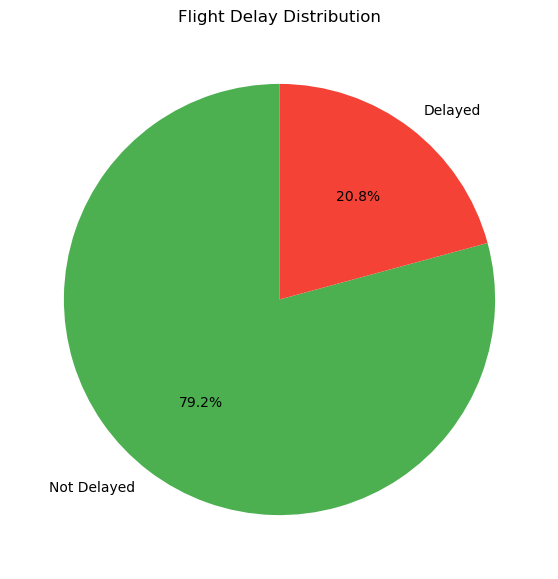

In [6]:
# Flight delay distribution

delay_counts = df_clean["ARR_DEL15"].value_counts().reindex([0, 1])

print("Not Delayed:", delay_counts[0])
print("Delayed:", delay_counts[1])

plt.figure(figsize=(7, 7))

plt.pie(
    delay_counts,
    labels=["Not Delayed", "Delayed"],
    autopct="%1.1f%%",
    colors=["#4CAF50", "#F44336"],
    startangle=90
)

plt.title("Flight Delay Distribution")
plt.show()

OP_UNIQUE_CARRIER
B6    31.638519
NK    28.125283
F9    27.974624
OH    24.270888
G4    24.047728
AA    23.970462
OO    23.092861
AS    21.043451
YX    20.426379
MQ    20.199773
DL    19.752696
UA    17.958698
WN    15.238331
Name: ARR_DEL15, dtype: float64

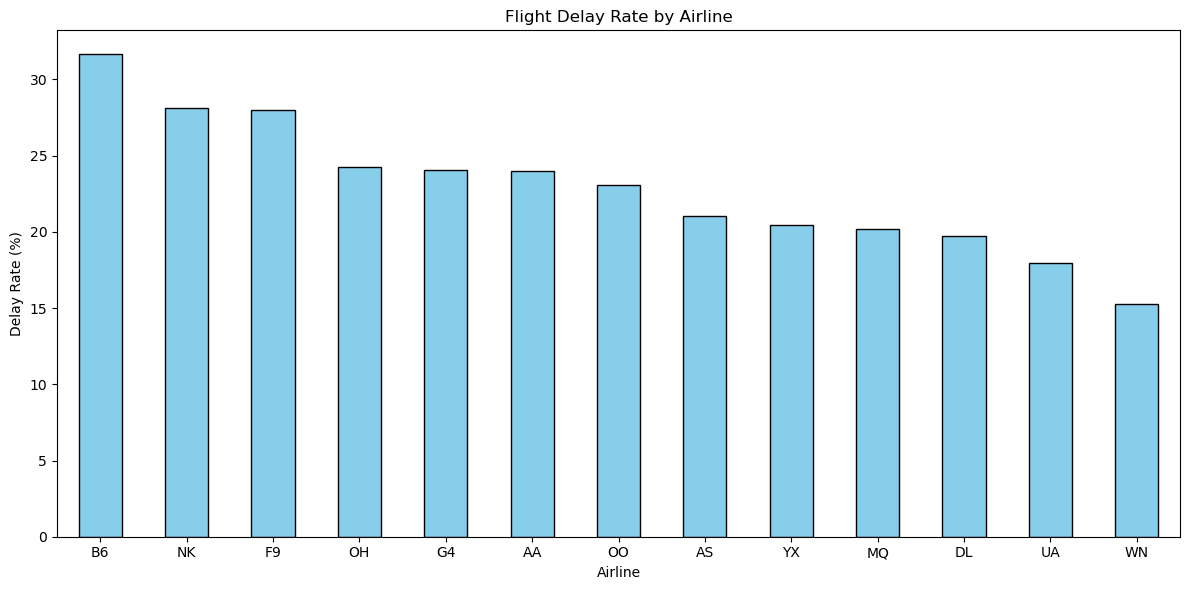

In [7]:
# Calculate delay rate by airline

airline_delay = (
    df_clean.groupby("OP_UNIQUE_CARRIER")
    ["ARR_DEL15"].mean() * 100
)

airline_delay = airline_delay.sort_values(
    ascending=False
)

display(airline_delay)

plt.figure(figsize=(12, 6))

airline_delay.plot(
    kind="bar",
    color="skyblue",
    edgecolor="black"
)

plt.title("Flight Delay Rate by Airline")
plt.xlabel("Airline")
plt.ylabel("Delay Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

DEP_HOUR
0     13.502110
1     20.762712
2     28.244275
3     27.777778
4     50.000000
5     11.012808
6     12.874810
7     15.094340
8     16.832134
9     17.842390
10    18.828361
11    19.840297
12    20.878491
13    21.656625
14    22.629705
15    24.010117
16    24.898159
17    24.909373
18    25.508833
19    26.150015
20    26.007142
21    25.073898
22    24.471892
23    18.000000
Name: ARR_DEL15, dtype: float64

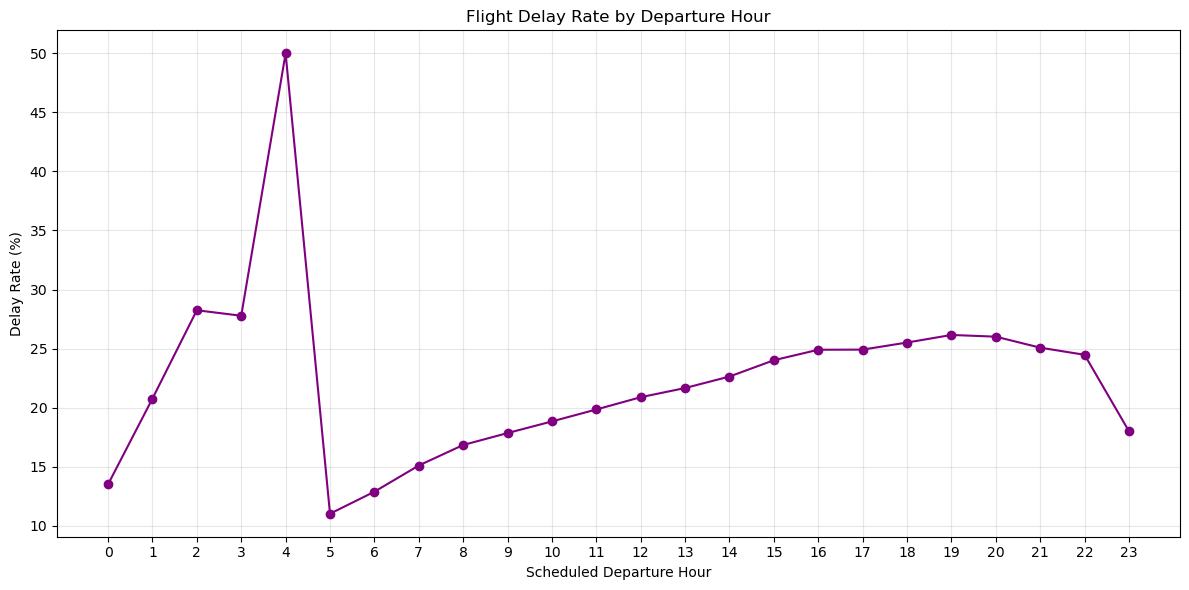

In [8]:
# Create departure hour feature
df_clean["DEP_HOUR"] = df_clean["CRS_DEP_TIME"] // 100

# Calculate delay rate by departure hour
hourly_delay = (
    df_clean.groupby("DEP_HOUR")["ARR_DEL15"].mean() * 100
)

display(hourly_delay)

plt.figure(figsize=(12, 6))

plt.plot(
    hourly_delay.index,
    hourly_delay.values,
    marker="o",
    color="purple"
)

plt.title("Flight Delay Rate by Departure Hour")
plt.xlabel("Scheduled Departure Hour")
plt.ylabel("Delay Rate (%)")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

DAY_OF_WEEK
Monday       24.484581
Tuesday      15.781325
Wednesday    15.297754
Thursday     19.182897
Friday       20.336248
Saturday     22.529348
Sunday       27.922937
Name: ARR_DEL15, dtype: float64

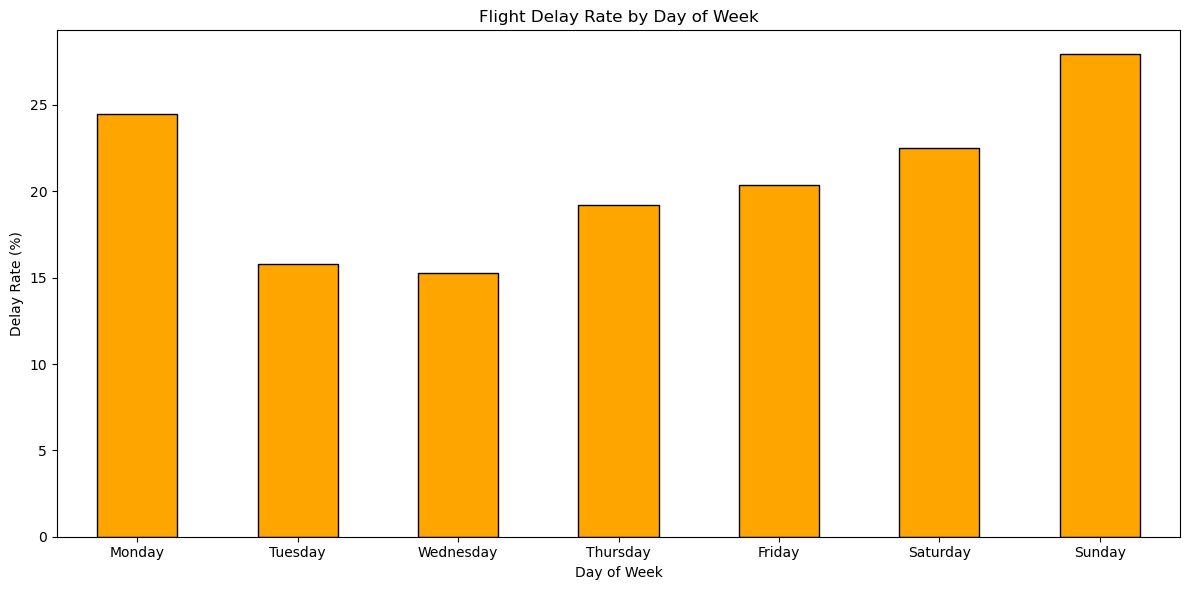

In [9]:
# Calculate delay rate by day of week

weekly_delay = (
    df_clean.groupby("DAY_OF_WEEK")
    ["ARR_DEL15"].mean() * 100
)

weekly_delay.index = weekly_delay.index.map({
    1: "Monday",
    2: "Tuesday",
    3: "Wednesday",
    4: "Thursday",
    5: "Friday",
    6: "Saturday",
    7: "Sunday"
})

display(weekly_delay)

plt.figure(figsize=(12, 6))

weekly_delay.plot(
    kind="bar",
    color="orange",
    edgecolor="black"
)

plt.title("Flight Delay Rate by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Delay Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

,mean,count,Delay_Rate
ORIGIN,,,
TVC,0.443983,241,44.398340
MBS,0.431034,174,43.103448
DLH,0.412281,114,41.228070
SBN,0.411765,612,41.176471
LAN,0.398734,158,39.873418
AZO,0.375000,136,37.500000
GRR,0.368499,1346,36.849926
RST,0.366337,101,36.633663
BGR,0.365079,126,36.507937


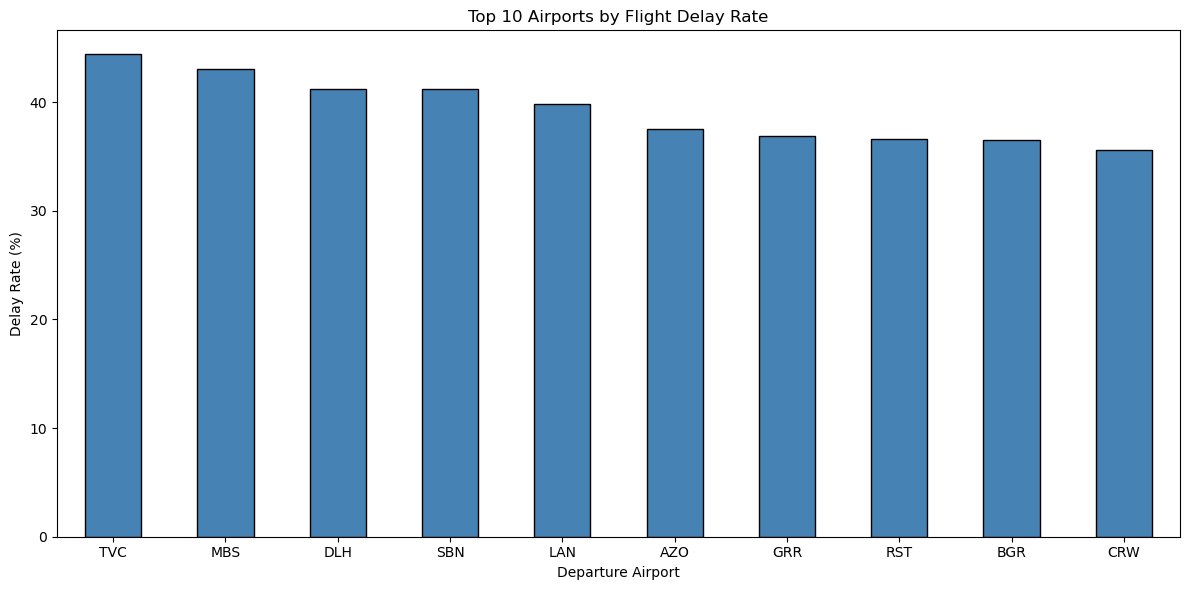

In [10]:
# Calculate delay rate by departure airport

airport_stats = df_clean.groupby("ORIGIN")["ARR_DEL15"].agg(
    ["mean", "count"]
)

# Include airports with at least 100 flights
airport_stats = airport_stats[
    airport_stats["count"] >= 100
].copy()

airport_stats["Delay_Rate"] = airport_stats["mean"] * 100

top_airports = airport_stats.sort_values(
    "Delay_Rate", ascending=False
).head(10)

display(top_airports)

plt.figure(figsize=(12, 6))

top_airports["Delay_Rate"].plot(
    kind="bar",
    color="steelblue",
    edgecolor="black"
)

plt.title("Top 10 Airports by Flight Delay Rate")
plt.xlabel("Departure Airport")
plt.ylabel("Delay Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [11]:
# Select features available before departure

features = [
    "DAY_OF_MONTH",
    "DAY_OF_WEEK",
    "OP_UNIQUE_CARRIER",
    "ORIGIN",
    "DEST",
    "CRS_DEP_TIME",
    "CRS_ARR_TIME",
    "CRS_ELAPSED_TIME",
    "DISTANCE",
    "DEP_HOUR"
]

model_data = df_clean.dropna(
    subset=features + ["ARR_DEL15"]
).copy()

# Input features
X = model_data[features].copy()

# Target variable
y = model_data["ARR_DEL15"].copy()

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nMissing Values:")
print(X.isnull().sum())

display(X.head())

Features Shape: (517222, 10)
Target Shape: (517222,)

Missing Values:
DAY_OF_MONTH         0
DAY_OF_WEEK          0
OP_UNIQUE_CARRIER    0
ORIGIN               0
DEST                 0
CRS_DEP_TIME         0
CRS_ARR_TIME         0
CRS_ELAPSED_TIME     0
DISTANCE             0
DEP_HOUR             0
dtype: int64


,DAY_OF_MONTH,DAY_OF_WEEK,OP_UNIQUE_CARRIER,ORIGIN,DEST,CRS_DEP_TIME,CRS_ARR_TIME,CRS_ELAPSED_TIME,DISTANCE,DEP_HOUR
0,1,4,AA,JFK,LAX,700,1021,381,2475,7
1,1,4,AA,LAX,JFK,2130,551,321,2475,21
2,1,4,AA,MIA,MSY,2245,2359,134,674,22
3,1,4,AA,DEN,MIA,2338,527,229,1709,23
4,1,4,AA,BOS,CLT,757,1030,153,728,7


In [12]:
# Split data chronologically

train_data = model_data[
    model_data["DAY_OF_MONTH"] <= 24
].sort_values("DAY_OF_MONTH")

test_data = model_data[
    model_data["DAY_OF_MONTH"] > 24
].sort_values("DAY_OF_MONTH")

X_train = train_data[features].copy()
X_test = test_data[features].copy()

y_train = train_data["ARR_DEL15"].copy()
y_test = test_data["ARR_DEL15"].copy()

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Data: (415240, 10)
Testing Data: (101982, 10)
Training Target: (415240,)
Testing Target: (101982,)


In [14]:
# Import machine learning libraries

from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Identify categorical features

categorical_features = [
    "OP_UNIQUE_CARRIER",
    "ORIGIN",
    "DEST"
]

# Identify numerical features

numerical_features = [
    col for col in features
    if col not in categorical_features
]

# Create preprocessing pipeline

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        )
    ]
)

print("Categorical Features:", categorical_features)
print("Numerical Features:", numerical_features)
print("Preprocessing Setup Completed!")

Categorical Features: ['OP_UNIQUE_CARRIER', 'ORIGIN', 'DEST']
Numerical Features: ['DAY_OF_MONTH', 'DAY_OF_WEEK', 'CRS_DEP_TIME', 'CRS_ARR_TIME', 'CRS_ELAPSED_TIME', 'DISTANCE', 'DEP_HOUR']
Preprocessing Setup Completed!


In [15]:
# Train Logistic Regression model

from sklearn.base import clone

lr_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

lr_model.fit(X_train, y_train)

print("Logistic Regression Training Completed!")


Logistic Regression Training Completed!


In [16]:
# Train Random Forest model

rf_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=50,
        max_depth=15,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest Training Completed!")


Random Forest Training Completed!


In [17]:
# Import evaluation metrics

from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

# Generate predictions

lr_pred = lr_model.predict(X_test)
rf_pred = rf_model.predict(X_test)

# Compare baseline model performance

results_df = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, lr_pred),
        accuracy_score(y_test, rf_pred)
    ],
    "Precision": [
        precision_score(y_test, lr_pred, zero_division=0),
        precision_score(y_test, rf_pred, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, lr_pred, zero_division=0),
        recall_score(y_test, rf_pred, zero_division=0)
    ],
    "F1 Score": [
        f1_score(y_test, lr_pred, zero_division=0),
        f1_score(y_test, rf_pred, zero_division=0)
    ]
})

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.6669,0.3780,0.3109,0.3412
1,Random Forest,0.6232,0.3525,0.4279,0.3865


In [22]:
from sklearn.model_selection import GridSearchCV

# Create chronological validation folds
days = X_train["DAY_OF_MONTH"].to_numpy()

cv = [
    (np.where(days <= 6)[0],
     np.where((days > 6) & (days <= 12))[0]),

    (np.where(days <= 12)[0],
     np.where((days > 12) & (days <= 18))[0]),

    (np.where(days <= 18)[0],
     np.where((days > 18) & (days <= 24))[0])
]

# Hyperparameter tuning
lr_search = GridSearchCV(
    estimator=lr_model,
    param_grid={
        "classifier__C": [0.01, 0.1, 1, 10]
    },
    cv=cv,
    scoring="f1",
    n_jobs=1
)

lr_search.fit(X_train, y_train)

print("Best Parameters:", lr_search.best_params_)
print("Best Validation F1 Score:", lr_search.best_score_)
print("Logistic Regression Tuning Completed!")

Best Parameters: {'classifier__C': 10}
Best Validation F1 Score: 0.1804837287265734
Logistic Regression Tuning Completed!


In [23]:
# Hyperparameter tuning for Random Forest

from sklearn.model_selection import RandomizedSearchCV

rf_search = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions={
        "classifier__n_estimators": [30, 50, 80],
        "classifier__max_depth": [10, 15, 20],
        "classifier__min_samples_leaf": [5, 10, 20]
    },
    n_iter=4,
    cv=cv,
    scoring="f1",
    random_state=42,
    n_jobs=1,
    verbose=1
)

rf_search.fit(X_train, y_train)

print("Best Parameters:", rf_search.best_params_)
print("Best Validation F1 Score:", rf_search.best_score_)
print("Random Forest Tuning Completed!")

Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best Parameters: {'classifier__n_estimators': 80, 'classifier__min_samples_leaf': 20, 'classifier__max_depth': 10}
Best Validation F1 Score: 0.27685266830637895
Random Forest Tuning Completed!


In [24]:
# Evaluate tuned models

best_lr = lr_search.best_estimator_
best_rf = rf_search.best_estimator_

models = {
    "Logistic Regression": best_lr,
    "Random Forest": best_rf
}

final_results = []

for name, model in models.items():

    predictions = model.predict(X_test)

    final_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

final_results_df = pd.DataFrame(final_results)

display(final_results_df.round(4))# Evaluate tuned models

best_lr = lr_search.best_estimator_
best_rf = rf_search.best_estimator_

models = {
    "Logistic Regression": best_lr,
    "Random Forest": best_rf
}

final_results = []

for name, model in models.items():

    predictions = model.predict(X_test)

    final_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

final_results_df = pd.DataFrame(final_results)

display(final_results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.6671,0.3785,0.3115,0.3417
1,Random Forest,0.6031,0.3445,0.4773,0.4002


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.6671,0.3785,0.3115,0.3417
1,Random Forest,0.6031,0.3445,0.4773,0.4002


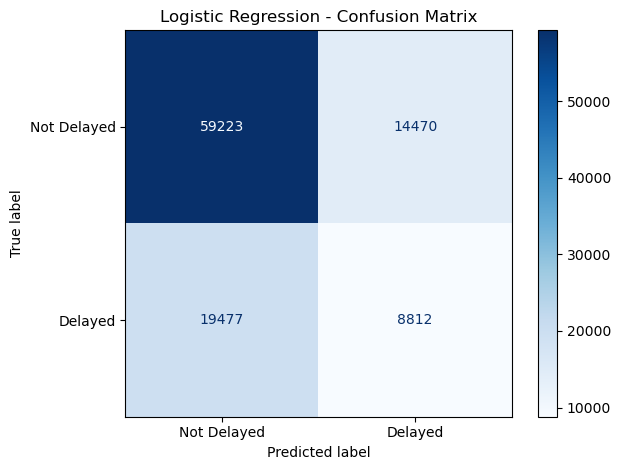

Logistic Regression
              precision    recall  f1-score   support

           0       0.75      0.80      0.78     73693
           1       0.38      0.31      0.34     28289

    accuracy                           0.67    101982
   macro avg       0.57      0.56      0.56    101982
weighted avg       0.65      0.67      0.66    101982



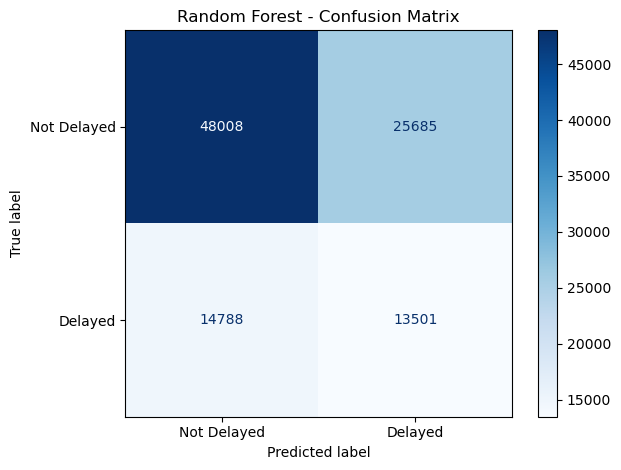

Random Forest
              precision    recall  f1-score   support

           0       0.76      0.65      0.70     73693
           1       0.34      0.48      0.40     28289

    accuracy                           0.60    101982
   macro avg       0.55      0.56      0.55    101982
weighted avg       0.65      0.60      0.62    101982



In [25]:
# Confusion Matrix for both tuned models

from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report

for name, model in models.items():

    predictions = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    )

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Not Delayed", "Delayed"]
    ).plot(cmap="Blues")

    plt.title(name + " - Confusion Matrix")
    plt.tight_layout()
    plt.show()

    print(name)

    print(classification_report(
        y_test,
        predictions,
        zero_division=0
    ))

In [26]:
import joblib
import sklearn

best_model = rf_search.best_estimator_

joblib.dump(
    best_model,
    "flight_delay_model.pkl",
    compress=3
)

final_results_df.to_csv(
    "Model_Results.csv",
    index=False
)

print("Best Model: Random Forest")
print("Model Saved Successfully!")

print("Scikit-learn Version:", sklearn.__version__)
print("Pandas Version:", pd.__version__)
print("NumPy Version:", np.__version__)
print("Joblib Version:", joblib.__version__)

Best Model: Random Forest
Model Saved Successfully!
Scikit-learn Version: 1.6.1
Pandas Version: 2.2.3
NumPy Version: 2.1.3
Joblib Version: 1.4.2
